# Experimento 1 — Extrapolación de longitud en memoria asociativa
## RoPE frente a *embeddings* posicionales absolutos aprendidos

**Práctica 1 — Procesamiento del Lenguaje Natural I**  
Informe experimental · Octubre de 2026

---

## 1. Introducción e hipótesis

El modelo base de `minigpt` es un decodificador transformer causal tipo GPT-2.
Con `positional="learned"` la posición se inyecta sumando a la incrustación
del token una **incrustación posicional absoluta entrenable**:

$$
x_i = \operatorname{tok\_emb}(t_i) + \operatorname{pos\_emb}(i),
\qquad \operatorname{pos\_emb}\in\mathbb{R}^{L_{\text{ctx}}\times d}.
$$

En `minigpt/model.py` esa tabla es `nn.Embedding(context_length, emb_dim)`.
Sus filas solo reciben gradiente para las posiciones que aparecen durante el
entrenamiento. Si se evalúa con secuencias más largas, las filas
correspondientes a posiciones no vistas conservan únicamente su
inicialización aleatoria $N(0,0.02)$ y actúan como ruido.

La variante `positional="rope"` elimina por completo `pos_emb`. La posición se
inyecta dentro de la atención rotando las consultas y las claves
(`minigpt/rope.py` y `minigpt/attention.py`). Para la posición $m$ y la
frecuencia $\theta_i=\text{base}^{-2i/d}$:

$$
q_m = R(\Theta_m)q,\qquad k_n = R(\Theta_n)k,
\qquad
q_m^\top k_n = q^\top R(\Theta_{n-m})k.
$$

El producto punto depende solo de la **diferencia relativa** $n-m$, no de las
posiciones absolutas. Además, `RoPECache._ensure_capacity` recalcula la caché
si se solicitan posiciones nuevas, por lo que no hay una tabla fija que se
quede “sin entrenar”.

### Tarea: *associative recall*

Cada secuencia contiene varios pares clave-valor (claves A–Z distintas,
valores 0–9) y una consulta. El modelo debe recuperar el valor asociado a la
clave consultada. El valor aparece **inmediatamente después** de la clave de
consulta y la flecha `->` actúa como terminador:

```text
 G: 4, T: 7, A: 2, Z: 9 QUERY A 2 ->
```

Esta colocación es deliberada: permite que una cabeza de inducción copie el
token que sigue a la aparición previa de la clave. En pruebas preliminares,
si se interpone un separador (`QUERY A -> 2` o `QUERY A: 2`) entre la clave y
el valor, el modelo pequeño no aprende la recuperación en varios saltos y se
queda en precisión de azar aunque memorice el *train*.

### Hipótesis

| ID | Hipótesis |
|----|-----------|
| **H1** | Ambos modelos superan el 95 % de *accuracy* en validación con longitudes vistas (4–6 pares). |
| **H2** | El modelo `learned` se degrada al extrapolar porque usa filas de `pos_emb` nunca entrenadas. |
| **H3** | RoPE conserva una precisión alta en longitudes no vistas gracias a la invariancia relativa de las rotaciones. |
| **H4** | RoPE es numéricamente invariante a traslación; `learned` no lo es. |


## 2. Configuración del entorno y carga de artefactos

Se cargan los conjuntos sintéticos, los historiales de entrenamiento y los
pesos guardados por `scripts/entrenamiento_exp1.py`. El vocabulario compacto se obtiene
del tokenizador BPE de GPT-2 (`tiktoken`) restringido a los 41 tokens de la
tarea, más un token de relleno.


In [1]:
import json
import warnings

warnings.filterwarnings("ignore", message=".*IProgress not found.*")
import math
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display

NOTEBOOK_DIR = Path.cwd()
if (NOTEBOOK_DIR / "data" / "dataset_asociativo.py").is_file():
    EXPERIMENT_DIR = NOTEBOOK_DIR
elif (NOTEBOOK_DIR / "experimento1_asociativo" / "data" / "dataset_asociativo.py").is_file():
    EXPERIMENT_DIR = NOTEBOOK_DIR / "experimento1_asociativo"
elif NOTEBOOK_DIR.name == "notebooks":
    EXPERIMENT_DIR = NOTEBOOK_DIR.parent
else:
    raise FileNotFoundError("No se encontró el directorio del experimento 1")
PROJECT_ROOT = EXPERIMENT_DIR.parent
for path in (EXPERIMENT_DIR, EXPERIMENT_DIR / "data", EXPERIMENT_DIR / "scripts", PROJECT_ROOT):
    if str(path) not in sys.path:
        sys.path.insert(0, str(path))

import dataset_asociativo as data
import entrenamiento_exp1 as training
from minigpt.experiments import translation_invariance_error

plt.rcParams.update({
    "figure.dpi": 120,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "font.size": 10,
})
COLORS = {"learned": "#d1495b", "rope": "#1f77b4"}
LABELS = {"learned": "Learned (pos. absolutas)", "rope": "RoPE (pos. relativas)"}
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

with (EXPERIMENT_DIR / "resultados_experimento1.json").open(encoding="utf-8") as handle:
    results = json.load(handle)
with (data.DATA_DIR / "metadata.json").open(encoding="utf-8") as handle:
    metadata = json.load(handle)

train = data.load_examples(data.DATA_DIR / "train.json")
val = data.load_examples(data.DATA_DIR / "val.json")
tests = {
    n_pairs: data.load_examples(data.DATA_DIR / f"test_pairs_{n_pairs}.json")
    for n_pairs in data.TEST_PAIR_LENGTHS
}
tokenizer = data.AssociativeTokenizer()

print("Dispositivo:", DEVICE)
print("Directorio del experimento:", EXPERIMENT_DIR)
print(f"Vocabulario compacto: {tokenizer.vocab_size} tokens (41 de tarea + <pad>)")
print("Tokens:", tokenizer.id_to_token)


Dispositivo: cuda
Directorio del experimento: /home/usuario/A4/PL/Practica1_PLN1/experimento1_asociativo
Vocabulario compacto: 42 tokens (41 de tarea + <pad>)
Tokens: [',', ':', ' T', ' S', ' I', ' A', ' C', ' M', ' B', ' P', ' 1', ' D', ' 2', ' H', ' W', ' R', ' F', ' N', ' G', ' L', ' E', ' O', ' J', ' U', ' K', ' 3', ' V', ' Y', ' 4', ' 5', ' 0', ' 6', ' 7', ' 8', ' 9', ' Z', ' Q', ' X', ' ->', ' QU', 'ERY', '<pad>']


## 3. Generación y exploración del dataset

Particiones usadas:

| Conjunto | Pares por secuencia | Ejemplos | Longitud en tokens |
|---|---|---:|---:|
| Entrenamiento | 4–6 | 10 000 | 20–28 |
| Validación in-distribution | 4–6 | 1 000 | 20–28 |
| Test de extrapolación | 6, 8, 12, 16, 20, 24 | 1 000 por longitud | 28, 36, 52, 68, 84, 100 |

La longitud en tokens sigue $4n+4$ para $n$ pares: cada par aporta
clave, `:`, valor y coma (salvo el último), y la consulta aporta
`QUERY`, clave, valor y `->`.


,conjunto,ejemplos,pares mín.,pares máx.,tokens mín.,tokens máx.,tokens medios
0,train,10000,4,6,20,28,23.98
1,validación,1000,4,6,20,28,24.10
2,test 6 pares,1000,6,6,28,28,28.00
3,test 8 pares,1000,8,8,36,36,36.00
4,test 12 pares,1000,12,12,52,52,52.00
5,test 16 pares,1000,16,16,68,68,68.00
6,test 20 pares,1000,20,20,84,84,84.00
7,test 24 pares,1000,24,24,100,100,100.00


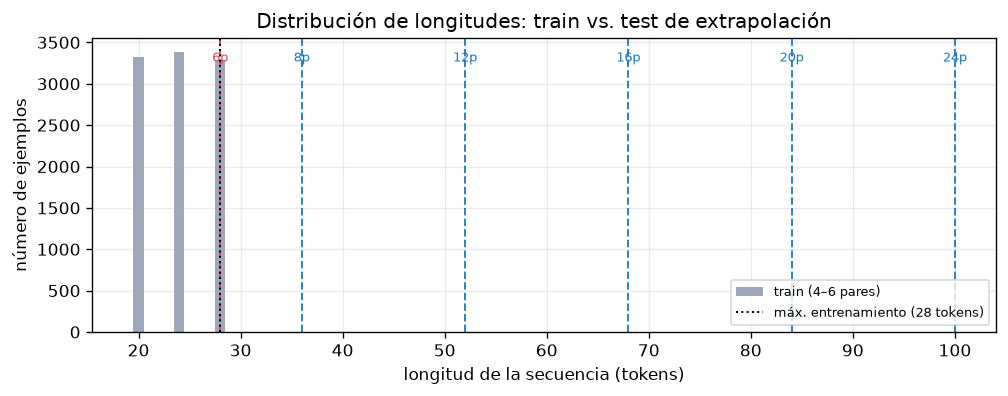

In [2]:
rows = []
for name, examples in (
    [("train", train), ("validación", val)]
    + [(f"test {n} pares", tests[n]) for n in data.TEST_PAIR_LENGTHS]
):
    stats = data.dataset_statistics(examples)
    rows.append({
        "conjunto": name,
        "ejemplos": int(stats["n_examples"]),
        "pares mín.": int(stats["min_pairs"]),
        "pares máx.": int(stats["max_pairs"]),
        "tokens mín.": int(stats["min_tokens"]),
        "tokens máx.": int(stats["max_tokens"]),
        "tokens medios": round(stats["mean_tokens"], 2),
    })
display(pd.DataFrame(rows))

fig, ax = plt.subplots(figsize=(8.5, 3.4))
train_lengths = [len(example.token_ids) for example in train]
test_lengths = [4 * n + 4 for n in data.TEST_PAIR_LENGTHS]
ax.hist(train_lengths, bins=np.arange(19.5, 30.5, 1), color="#8d99ae",
        alpha=0.85, label="train (4–6 pares)")
for n_pairs, length in zip(data.TEST_PAIR_LENGTHS, test_lengths):
    ax.axvline(length, color=COLORS["rope"] if n_pairs > 6 else COLORS["learned"],
               ls="--", linewidth=1.2, alpha=0.9)
    ax.text(length, ax.get_ylim()[1] * 0.92, f"{n_pairs}p", ha="center",
            fontsize=8, color=COLORS["rope"] if n_pairs > 6 else COLORS["learned"])
ax.axvline(28, color="black", ls=":", linewidth=1.2, label="máx. entrenamiento (28 tokens)")
ax.set_xlabel("longitud de la secuencia (tokens)")
ax.set_ylabel("número de ejemplos")
ax.set_title("Distribución de longitudes: train vs. test de extrapolación")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()


### 3.1 Formato exacto y posición de la respuesta

La respuesta es el **penúltimo** token (el último es la flecha). Por tanto,
`answer_position = len(token_ids) - 2`. El modelo predice ese token con el
logit de la posición anterior, que coincide con la clave de la consulta. Así
la cabeza de inducción solo necesita copiar el token que siguió a la aparición
previa de esa misma clave.


In [3]:
print("Ejemplos de entrenamiento (4–6 pares):")
for example in train[:2]:
    print(" texto :", example.text)
    print(" tokens:", [tokenizer.id_to_token[i] for i in example.token_ids])
    print(f" respuesta: {tokenizer.id_to_token[example.token_ids[example.answer_position]]!r} "
          f"en la posición {example.answer_position} (penúltima); "
          f"flecha final: {tokenizer.id_to_token[example.token_ids[-1]]!r}")
    print()

print("Ejemplo de extrapolación (24 pares, 100 tokens):")
example = tests[24][0]
print(" texto :", example.text)
print(" tokens:", [tokenizer.id_to_token[i] for i in example.token_ids])
print(f" respuesta: {tokenizer.id_to_token[example.token_ids[example.answer_position]]!r} "
      f"en la posición {example.answer_position}; flecha final: "
      f"{tokenizer.id_to_token[example.token_ids[-1]]!r}")
print(f" longitud total: {len(example.token_ids)} tokens")


Ejemplos de entrenamiento (4–6 pares):
 texto :  K: 3, Q: 9, U: 9, D: 8 QUERY D 8 ->
 tokens: [' K', ':', ' 3', ',', ' Q', ':', ' 9', ',', ' U', ':', ' 9', ',', ' D', ':', ' 8', ' QU', 'ERY', ' D', ' 8', ' ->']
 respuesta: ' 8' en la posición 18 (penúltima); flecha final: ' ->'

 texto :  R: 0, X: 9, P: 1, S: 1, O: 4, H: 1 QUERY S 1 ->
 tokens: [' R', ':', ' 0', ',', ' X', ':', ' 9', ',', ' P', ':', ' 1', ',', ' S', ':', ' 1', ',', ' O', ':', ' 4', ',', ' H', ':', ' 1', ' QU', 'ERY', ' S', ' 1', ' ->']
 respuesta: ' 1' en la posición 26 (penúltima); flecha final: ' ->'

Ejemplo de extrapolación (24 pares, 100 tokens):
 texto :  W: 1, L: 5, G: 4, F: 4, M: 0, N: 8, K: 6, V: 7, T: 3, Q: 0, I: 4, X: 5, Z: 2, A: 1, H: 0, E: 8, Y: 3, O: 8, P: 8, J: 1, R: 0, U: 8, S: 5, C: 0 QUERY V 7 ->
 tokens: [' W', ':', ' 1', ',', ' L', ':', ' 5', ',', ' G', ':', ' 4', ',', ' F', ':', ' 4', ',', ' M', ':', ' 0', ',', ' N', ':', ' 8', ',', ' K', ':', ' 6', ',', ' V', ':', ' 7', ',', ' T', ':', ' 3', ',', 

## 4. Configuración y entrenamiento

Ambos modelos comparten arquitectura, inicialización y datos; la **única**
diferencia es el esquema posicional. La comprobación de inicialización común
del script encontró 72 tensores comunes con diferencia máxima exactamente
$0$. El modelo `learned` añade la tabla `pos_emb` (256 × 128 = 32 768
parámetros); RoPE no tiene parámetros posicionales.

El entrenamiento usa AdamW ($\text{lr}=10^{-3}$, *weight decay* $0.01$),
calentamiento de 100 pasos, decaimiento coseno, lote de 64 y pérdida de
entropía cruzada **solo en el token de respuesta**. Se ejecutaron 4 000 pasos
por modelo.


,variante,positional,vocab_size,context_length,emb_dim,n_heads,n_layers,params posicionales,parámetros totales
0,Learned (pos. absolutas),learned,42,256,128,4,4,32768,836864
1,RoPE (pos. relativas),rope,42,256,128,4,4,0,804096


Checkpoints cargados:
  Learned (pos. absolutas)     /home/usuario/A4/PL/Practica1_PLN1/experimento1_asociativo/pesos/learned/best_model.pt  (4.4 MB)
  RoPE (pos. relativas)        /home/usuario/A4/PL/Practica1_PLN1/experimento1_asociativo/pesos/rope/best_model.pt  (4.3 MB)


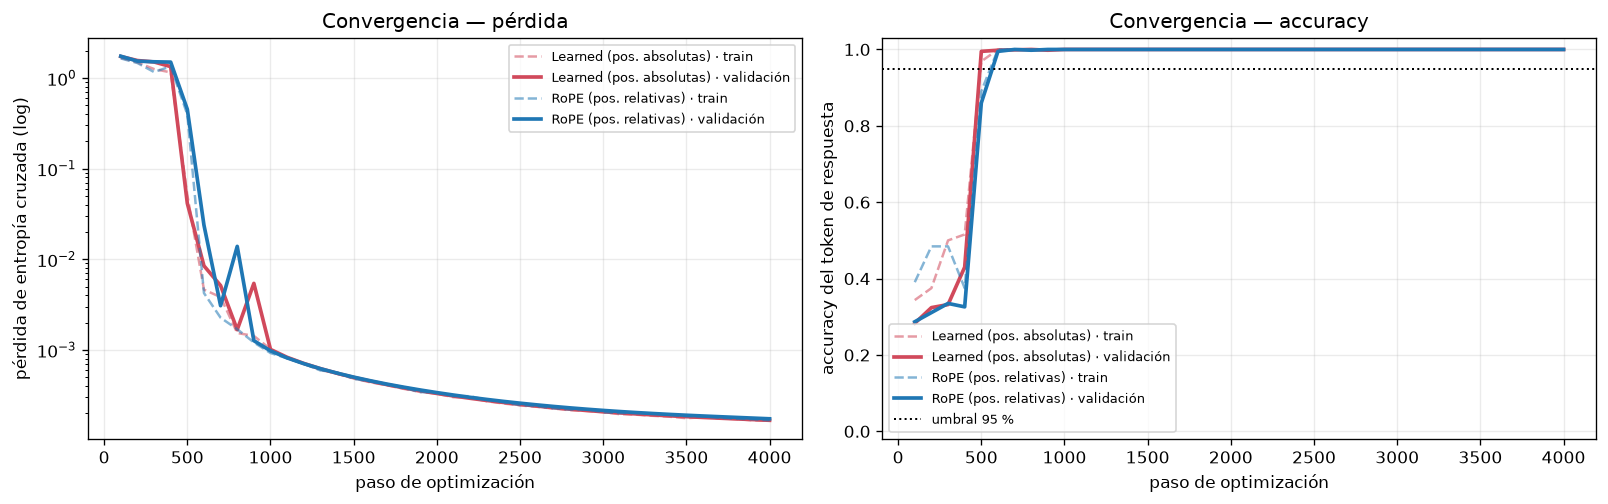

Resumen de entrenamiento:
  Learned (pos. absolutas)     mejor paso=4000  val_loss=0.000167  val_acc=100.00%  tiempo=80.1 s
  RoPE (pos. relativas)        mejor paso=4000  val_loss=0.000174  val_acc=100.00%  tiempo=87.9 s


In [4]:
checkpoints = {}
for positional in ("learned", "rope"):
    path = data.WEIGHTS_ROOT / positional / "best_model.pt"
    model, history, payload = training.load_checkpoint(path, device=DEVICE)
    checkpoints[positional] = {
        "model": model,
        "history": history,
        "payload": payload,
        "path": path,
    }

config_rows = []
for positional, info in checkpoints.items():
    cfg = info["model"].cfg
    config_rows.append({
        "variante": LABELS[positional],
        "positional": cfg.positional,
        "vocab_size": cfg.vocab_size,
        "context_length": cfg.context_length,
        "emb_dim": cfg.emb_dim,
        "n_heads": cfg.n_heads,
        "n_layers": cfg.n_layers,
        "params posicionales": info["model"].positional_parameters,
        "parámetros totales": sum(p.numel() for p in info["model"].parameters()),
    })
display(pd.DataFrame(config_rows))

print("Checkpoints cargados:")
for positional, info in checkpoints.items():
    size_mb = info["path"].stat().st_size / 1e6
    print(f"  {LABELS[positional]:<28} {info['path']}  ({size_mb:.1f} MB)")

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.3))
for positional, info in checkpoints.items():
    history = info["history"]
    axes[0].plot(history.steps, history.train_losses, "--",
                 color=COLORS[positional], alpha=0.55,
                 label=f"{LABELS[positional]} · train")
    axes[0].plot(history.val_steps, history.val_losses, "-",
                 color=COLORS[positional], linewidth=2.2,
                 label=f"{LABELS[positional]} · validación")
    axes[1].plot(history.steps, history.train_accuracies, "--",
                 color=COLORS[positional], alpha=0.55,
                 label=f"{LABELS[positional]} · train")
    axes[1].plot(history.val_steps, history.val_accuracies, "-",
                 color=COLORS[positional], linewidth=2.2,
                 label=f"{LABELS[positional]} · validación")

axes[0].set_yscale("log")
axes[0].set_xlabel("paso de optimización")
axes[0].set_ylabel("pérdida de entropía cruzada (log)")
axes[0].set_title("Convergencia — pérdida")
axes[0].legend(fontsize=8)

axes[1].axhline(0.95, color="black", ls=":", linewidth=1.2, label="umbral 95 %")
axes[1].set_xlabel("paso de optimización")
axes[1].set_ylabel("accuracy del token de respuesta")
axes[1].set_title("Convergencia — accuracy")
axes[1].set_ylim(-0.02, 1.03)
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

print("Resumen de entrenamiento:")
for positional, info in checkpoints.items():
    history = info["history"]
    print(f"  {LABELS[positional]:<28} mejor paso={history.best_step:4d}  "
          f"val_loss={history.best_val_loss:.6f}  "
          f"val_acc={history.best_val_accuracy:.2%}  "
          f"tiempo={history.elapsed_seconds:.1f} s")


## 5. Evaluación de extrapolación de longitud

Se evalúa el *accuracy* exacto del token de respuesta en los conjuntos de test
con longitudes crecientes. La longitud 6 está dentro del rango de
entrenamiento (4–6 pares); 8, 12, 16, 20 y 24 son longitudes no vistas.


In [5]:
length_rows = []
for n_pairs in data.TEST_PAIR_LENGTHS:
    row = {"pares": n_pairs, "tokens": 4 * n_pairs + 4}
    for positional, info in checkpoints.items():
        metrics = training.evaluate_recall(
            info["model"], tests[n_pairs], tokenizer, device=DEVICE
        )
        row[f"{positional}_acc"] = metrics["accuracy"]
        row[f"{positional}_loss"] = metrics["loss"]
    length_rows.append(row)
df_length = pd.DataFrame(length_rows)

view = pd.DataFrame({
    "Pares": df_length["pares"],
    "Tokens": df_length["tokens"],
    "Learned acc": df_length["learned_acc"].map(lambda x: f"{x:.2%}"),
    "RoPE acc": df_length["rope_acc"].map(lambda x: f"{x:.2%}"),
    "Δ (RoPE − Learned)": (df_length["rope_acc"] - df_length["learned_acc"]).map(
        lambda x: f"{x:+.2%}"
    ),
    "Learned loss": df_length["learned_loss"].map(lambda x: f"{x:.4f}"),
    "RoPE loss": df_length["rope_loss"].map(lambda x: f"{x:.4f}"),
})
display(view)

saved = results["evaluations"]
max_diff = max(
    abs(df_length.loc[i, f"{positional}_acc"]
        - saved[positional]["by_length"][str(n_pairs)]["accuracy"])
    for i, n_pairs in enumerate(data.TEST_PAIR_LENGTHS)
    for positional in ("learned", "rope")
)
print(f"Verificación frente a los resultados guardados: "
      f"diferencia máxima de accuracy = {max_diff:.2e}")

print("Validación in-distribution (4–6 pares):")
for positional, info in checkpoints.items():
    metrics = training.evaluate_recall(info["model"], val, tokenizer, device=DEVICE)
    print(f"  {LABELS[positional]:<28} loss={metrics['loss']:.6f}  "
          f"accuracy={metrics['accuracy']:.2%}")


,Pares,Tokens,Learned acc,RoPE acc,Δ (RoPE − Learned),Learned loss,RoPE loss
0,6,28,100.00%,100.00%,+0.00%,0.0002,0.0002
1,8,36,73.70%,100.00%,+26.30%,1.7643,0.0002
2,12,52,48.40%,98.40%,+50.00%,3.8169,0.0734
3,16,68,41.00%,94.70%,+53.70%,4.3138,0.2485
4,20,84,35.70%,88.40%,+52.70%,4.6401,0.6173
5,24,100,31.10%,83.70%,+52.60%,5.0153,0.8877


Verificación frente a los resultados guardados: diferencia máxima de accuracy = 0.00e+00
Validación in-distribution (4–6 pares):
  Learned (pos. absolutas)     loss=0.000167  accuracy=100.00%


  RoPE (pos. relativas)        loss=0.000174  accuracy=100.00%


## 6. Visualización de resultados

La figura principal compara el *accuracy* y la pérdida en función de la
longitud. La zona sombreada corresponde a longitudes no vistas durante el
entrenamiento.


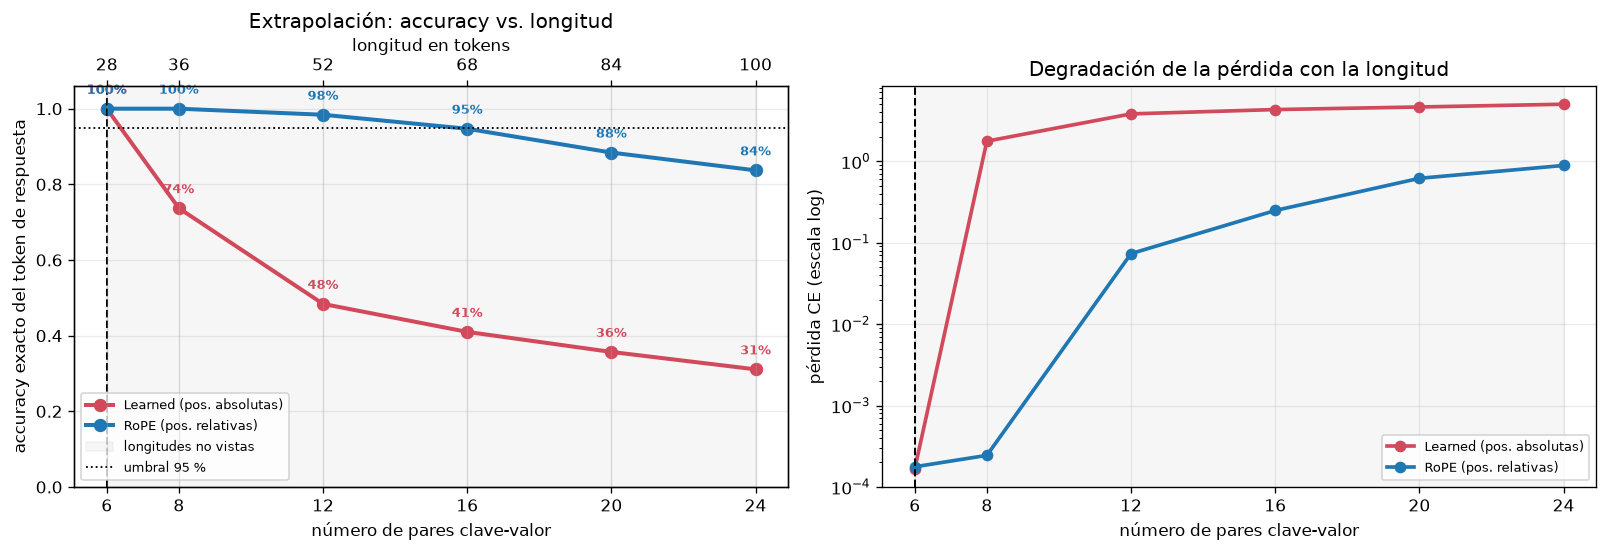

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.7))

ax = axes[0]
for positional in ("learned", "rope"):
    ax.plot(df_length["pares"], df_length[f"{positional}_acc"],
            marker="o", linewidth=2.4, markersize=7,
            color=COLORS[positional], label=LABELS[positional])
    for x, y in zip(df_length["pares"], df_length[f"{positional}_acc"]):
        ax.annotate(f"{y:.0%}", (x, y), textcoords="offset points",
                    xytext=(0, 9), ha="center", fontsize=8,
                    color=COLORS[positional], fontweight="bold")
ax.axvline(6, color="black", ls="--", linewidth=1.2)
ax.axvspan(6, 24, color="gray", alpha=0.07, label="longitudes no vistas")
ax.axhline(0.95, color="black", ls=":", linewidth=1.1, label="umbral 95 %")
ax.set_xlabel("número de pares clave-valor")
ax.set_ylabel("accuracy exacto del token de respuesta")
ax.set_title("Extrapolación: accuracy vs. longitud")
ax.set_xticks(df_length["pares"])
ax.set_ylim(0.0, 1.06)
ax.legend(loc="lower left", fontsize=8)
ax_top = ax.twiny()
ax_top.set_xlim(ax.get_xlim())
ax_top.set_xticks(df_length["pares"])
ax_top.set_xticklabels(df_length["tokens"])
ax_top.set_xlabel("longitud en tokens")

ax = axes[1]
for positional in ("learned", "rope"):
    ax.plot(df_length["pares"], df_length[f"{positional}_loss"],
            marker="o", linewidth=2.2, color=COLORS[positional],
            label=LABELS[positional])
ax.set_yscale("log")
ax.set_xlabel("número de pares clave-valor")
ax.set_ylabel("pérdida CE (escala log)")
ax.set_title("Degradación de la pérdida con la longitud")
ax.set_xticks(df_length["pares"])
ax.axvline(6, color="black", ls="--", linewidth=1.2)
ax.axvspan(6, 24, color="gray", alpha=0.07)
ax.legend(fontsize=8)

plt.tight_layout()
plt.show()


### 6.1 Diagnóstico: filas de `pos_emb` e invariancia a traslación

El modelo `learned` solo usó posiciones 0–27 durante el entrenamiento (28
tokens como máximo). Las filas 28–255 de `pos_emb` no recibieron gradiente y
conservan la inicialización $N(0,0.02)$: su norma media es claramente menor
que la de las filas entrenadas. Además, al desplazar la ventana de posiciones,
RoPE debe dejar los logits prácticamente intactos, mientras que `learned` no.


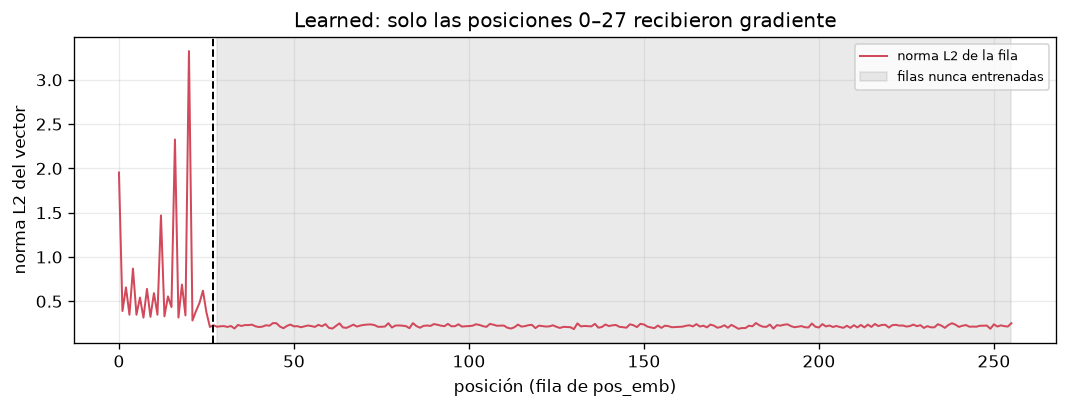

Posiciones entrenadas: 0..27 (28 filas)
Posiciones sin entrenar: 28..255 (228 filas)
Norma media de las filas entrenadas   : 0.7037
Norma media de las filas sin entrenar : 0.2210

Error máximo de logits al desplazar la ventana 10 posiciones (misma secuencia, mismas claves/valores):
  Learned (pos. absolutas)     error = 1.114e+01
  RoPE (pos. relativas)        error = 4.530e-06


In [7]:
learned_model = checkpoints["learned"]["model"]
wpe_norms = learned_model.pos_emb.weight.detach().cpu().norm(dim=1).numpy()
max_train_tokens = 4 * data.TRAIN_PAIRS[1] + 4  # 28

fig, ax = plt.subplots(figsize=(9.0, 3.5))
ax.plot(wpe_norms, color=COLORS["learned"], linewidth=1.2,
        label="norma L2 de la fila")
ax.axvspan(max_train_tokens, len(wpe_norms) - 1, color="gray", alpha=0.16,
           label="filas nunca entrenadas")
ax.axvline(max_train_tokens - 1, color="black", ls="--", linewidth=1.2)
ax.set_xlabel("posición (fila de pos_emb)")
ax.set_ylabel("norma L2 del vector")
ax.set_title(f"Learned: solo las posiciones 0–{max_train_tokens - 1} recibieron gradiente")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

print(f"Posiciones entrenadas: 0..{max_train_tokens - 1} "
      f"({max_train_tokens} filas)")
print(f"Posiciones sin entrenar: {max_train_tokens}.."
      f"{learned_model.cfg.context_length - 1} "
      f"({learned_model.cfg.context_length - max_train_tokens} filas)")
print(f"Norma media de las filas entrenadas   : "
      f"{wpe_norms[:max_train_tokens].mean():.4f}")
print(f"Norma media de las filas sin entrenar : "
      f"{wpe_norms[max_train_tokens:].mean():.4f}")

sample_inputs, _, _ = data.collate_examples(
    val[:8], tokenizer.pad_id, device=DEVICE
)
offset = 10
print(f"\nError máximo de logits al desplazar la ventana {offset} posiciones "
      f"(misma secuencia, mismas claves/valores):")
for positional, info in checkpoints.items():
    error = translation_invariance_error(info["model"], sample_inputs, offset=offset)
    print(f"  {LABELS[positional]:<28} error = {error:.3e}")


## 7. Análisis y conclusiones

### Resultados principales

| Fenómeno | Observación |
|---|---|
| Aprendizaje en longitudes vistas | Ambos modelos alcanzan **100 %** de validación (4–6 pares). |
| Extrapolación a 8 pares | `learned` cae al **73,7 %**; RoPE mantiene el **100 %**. |
| Extrapolación a 24 pares (4×) | `learned` cae al **31,1 %**; RoPE conserva el **83,7 %**. |
| Invariancia a traslación (offset 10) | `learned`: error máximo de logits ≈ **11,14**; RoPE ≈ **4,5·10⁻⁶**. |
| Parámetros posicionales | `learned`: **32 768**; RoPE: **0**. |

### Interpretación

1. **H1 confirmada.** Con el formato de valor inmediatamente posterior a la
   clave, ambos modelos aprenden la tarea en las longitudes de entrenamiento y
   superan ampliamente el 95 % de validación.

2. **H2 confirmada.** En `GPTModel.forward`, la variante `learned` suma
   `pos_emb(positions)`. Durante el entrenamiento solo se actualizan las filas
   0–27; las filas 28–255 conservan el ruido inicial. Al evaluar con 8–24
   pares, las posiciones de las claves, la consulta y la respuesta caen en esas
   filas no entrenadas, por lo que la señal posicional deja de ser informativa
   y el *accuracy* cae de forma monótona hasta el 31,1 %.

3. **H3 confirmada.** En `MultiHeadAttention.forward`, RoPE rota $Q$ y $K$
   mediante `apply_rotary` y `RoPECache.get`. El producto punto
   $q_m^\top k_n$ depende solo de $n-m$, de modo que la relación “clave
   consultada ↔ aparición previa de la clave” se conserva aunque la secuencia
   sea más larga. La caché de senos/cosenos se recalcula si hace falta, sin
   filas aleatorias sin entrenar. Por eso RoPE mantiene el 83,7 % a 24 pares.

4. **H4 confirmada.** El error de invariancia a traslación de RoPE es del orden
   del error de punto flotante ($10^{-6}$), mientras que el modelo `learned`
   cambia sus logits de forma apreciable (error ≈ 11,14) al desplazar la
   ventana de posiciones. Es la manifestación numérica directa de la ecuación
   relativa de RoPE.

### Por qué el modelo `learned` no se recupera

No basta con reservar un `context_length` grande: la tabla `pos_emb` es un
parámetro aprendido y las posiciones nuevas no tienen datos de entrenamiento.
Aumentar `context_length` evita el `IndexError`, pero no inventa
representaciones posicionales útiles. En cambio, RoPE no tiene una tabla que
“se quede corta”: las rotaciones para posiciones nuevas se calculan
analíticamente a partir de $\theta_i$ y el mismo conjunto de frecuencias.

### Limitaciones

* La tarea es sintética y los modelos son pequeños (4 capas, 128 dimensiones);
  la tendencia cualitativa es clara, pero la magnitud exacta depende de la
  escala y del número de semillas.
* La evaluación llega hasta 24 pares (100 tokens), 4× la longitud máxima de
  entrenamiento. RoPE también se degrada suavemente (100 % → 83,7 %), lo que
  sugiere una pérdida adicional por dilución de atención al aumentar el número
  de distractores, no por falta de información posicional.
* El formato de la consulta se eligió para que una cabeza de inducción de un
  modelo pequeño pudiera aprender la asociación. Con separadores intermedios
  (`QUERY A -> 2`) el modelo pequeño no aprendió la recuperación en dos
  saltos; ese fenómeno queda documentado como decisión metodológica.

### Conclusión

El experimento confirma empíricamente la superioridad de **RoPE** frente a los
*embeddings* posicionales absolutos aprendidos para la extrapolación de
longitud en memoria asociativa. Ambos modelos son equivalentes en las
longitudes vistas, pero solo RoPE conserva una precisión alta cuando la
consulta y las claves aparecen en posiciones que el modelo nunca vio durante
el entrenamiento.


---
*Reproducibilidad.* Los datos, pesos e historiales se generan con
`experimento1_asociativo/scripts/entrenamiento_exp1.py`. Las semillas son 2026 (datos),
42 (inicialización) y 123 (lotes de entrenamiento). Los pesos se guardan en
`experimento1_asociativo/pesos/{learned,rope}/best_model.pt` y los
resultados completos en `experimento1_asociativo/resultados_experimento1.json`.
